# 50只股票、三小时云端方法先导

本 Notebook 默认只读取课程中的协议、公开状态与已发布汇总。**不读取实验室数据，不登录或提交云任务，不启动计时。**重新运行单元格只更新本地展示；不是恢复或重发云实验的入口。

本轮问题是：在限定资源内，能否完成8比特QuKerNet方法链，并观察微调、随机搜索对照与股票分类之间的差异。50只股票并不代表量子核使用这50只股票的全部历史：核模型训练16条、验证16条、评价50条；全训练历史用于训练内特征选择、缩放及额外经典基线。

学习目标：复算实际计费对象；区分预算与消耗；辨认训练KTA、验证诊断和后续预测；按证据状态处理未完成实验。

In [1]:
from pathlib import Path
import json
from IPython.display import Markdown, Image, display

relative=Path('experiments/qukernet_finance/cloud_v3/protocol.json')
root=next((p for p in (Path.cwd(),*Path.cwd().parents) if (p/relative).is_file()),None)
if root is None:
    raise FileNotFoundError('请在课程仓库或其子目录打开本 Notebook。')
protocol=json.loads((root/relative).read_text(encoding='utf-8'))
reports=root/'reports/qukernet_cloud_v3'
status_path=reports/'status.json'
status=json.loads(status_path.read_text(encoding='utf-8')) if status_path.is_file() else {}
assert protocol['schema']=='compact_pilot_v3'
assert protocol['model']['qubits']==8 and protocol['data']['selected_features']==8
print('协议：',protocol['protocol_id'])
print('数据跨度：2019年起至来源与交易日历共同核实的最新日期。')
print('本 Notebook 未读取数据源，也未发起云请求。')

协议： qukernet-50stocks-3h-20261115-v1
数据跨度：2019年起至来源与交易日历共同核实的最新日期。
本 Notebook 未读取数据源，也未发起云请求。


## 1. 固定数据与模型设计

50只股票按验证开始前可知的信息、交易所比例与种子20261115选定，不按之后的数据完整性换股。评价区间为最新63个标签已成熟的市场交易日，之前63日为验证区间；训练从2019年起，跨界标签按实际结束日期净化。最新日期、抽样规模和固定样本覆盖以第2节的数据核查记录为准；名单仍保留在私有证据中。

每次收盘后生成特征，标签为次日开盘至第6个交易日开盘收益是否大于0。80项候选特征中，仅用训练期选择8项并缩放。50条评价记录分布在10个预定日期、每天5只股票，每只股票只评价一次；缺失固定记录时阻止启动而不补抽。

QuKerNet有6条KTA标签，其中4条训练神经评分器、2条诊断；经典预测256条新候选后实测1条入围线路。随机搜索独立测量7条训练核，取训练KTA最高者。两臂均仅一个微调配置，固定两个替换参数、两步更新，每步4条样本且每类2条，两臂共享预先冻结的批次。全部云概率线路512 shots。

本轮验证集只诊断唯一终点，不承担多个量子配置选优。RBF经典基线仍按预定γ集合0.1、1、10在验证集选择；这是独立且预先声明的规则。

In [2]:
execution=protocol['execution']
train_pairs=16*15//2
micro_pairs=4*3//2
gradient_per_step=micro_pairs*2*2*2  # 样本对×参数数×两端×正负移位
common=7*train_pairs+train_pairs+2*(micro_pairs+gradient_per_step)+train_pairs+16*16
qukernet=common+2*50*16
random=common+50*16
preflight=4
total=qukernet+random+preflight
assert (common,qukernet,random,total)==(1444,3044,2244,5292)
assert total==execution['max_circuits']
assert total*512==execution['max_requested_shots']==2709504
lines=['|用途|计划线路|计划请求 shots|','|---|---:|---:|',
       f'|QuKerNet及同配置初值评价|{qukernet:,}|{qukernet*512:,}|',
       f'|随机搜索|{random:,}|{random*512:,}|',
       f'|解析预检|{preflight:,}|{preflight*512:,}|',
       f'|总上限|{total:,}|{total*512:,}|']
display(Markdown('\n'.join(lines)))
print('两臂搜索与微调的公共配额各1444条。QuKerNet多出的800条用于自身初值O评价。')
print('因此两臂全流程总耗时与总shots不相同。上述为计划上限，不是实测消耗。')

|用途|计划线路|计划请求 shots|
|---|---:|---:|
|QuKerNet及同配置初值评价|3,044|1,558,528|
|随机搜索|2,244|1,148,928|
|解析预检|4|2,048|
|总上限|5,292|2,709,504|

两臂搜索与微调的公共配额各1444条。QuKerNet多出的800条用于自身初值O评价。
因此两臂全流程总耗时与总shots不相同。上述为计划上限，不是实测消耗。


## 2. 看真实状态，保留“尚未完成”

下面只展示公开状态文件的已保存字段，时间以 `observed_utc` 为准。旧实验与本轮新窗口单列，旧消耗不清零，也不当成本轮预测结果。数据来源恢复可读，不等于已经冻结50股数据，更不等于云实验已经开始。

新窗口首次预约启动三小时总计时，每批从预约至核验最多300秒；提交不明、失败、异常或到期即停止新增提交和自动轮询。无取消端点时，客户端停止不表示后台任务已取消。

In [3]:
if not status:
    print('未发现公开状态文件：当前运行状态尚未核实，效果结果待核查。')
else:
    labels={'data_preparation':'数据准备中','blocked':'条件未满足','blocked_data_coverage':'数据覆盖未通过，未启动云实验','running':'执行中','complete':'流程完成','stopped':'已停止'}
    state=status.get('state','unknown')
    print('保存的观察时间（UTC）：',status.get('observed_utc','未记录'))
    print('状态：',labels.get(state,state))
    print('来源可读状态：',status.get('source_access','未记录'))
    print('最新数据日期：',status.get('latest_date','未冻结'))
    print('新窗口已启动：',status.get('new_window_started','未记录'))
    print('新线路数：',status.get('new_cloud_circuits','未知'))
    print('新请求shots：',status.get('new_requested_shots','未知'))
    old=status.get('old_experiment',{})
    if old:
        print('旧实验：',old.get('state','未知'),'；线路',old.get('circuits','未知'),
              '；请求shots',old.get('requested_shots','未知'),'；未决',old.get('unresolved','未知'))
    print('效果汇总可用：',status.get('research_results_available',False))
    if status.get('summary_zh'):
        print('保存的核查结论：',status['summary_zh'])
    checks=status.get('offline_checks',{})
    if checks:
        print('离线构造/模拟测试：',checks.get('tests','未知'),'项；失败',checks.get('failures','未知'),
              '；错误',checks.get('errors','未知'),'。这不是金融预测结果。')
    if not status.get('research_results_available',False):
        print('当前公开状态尚未提供完成的效果结果；微调和股票预测效果待实测。')

保存的观察时间（UTC）： 2026-11-14T20:30:09.486554+00:00
状态： 数据覆盖未通过，未启动云实验
来源可读状态： restored
最新数据日期： 2026-11-13
新窗口已启动： False
新线路数： 0
新请求shots： 0
旧实验： superseded_and_stopped ；线路 6960 ；请求shots 3563520 ；未决 0
效果汇总可用： False
保存的核查结论： 已核实行情截止2026年11月13日并冻结50股。50只均缺同一组16个开市日；验证区无特征合格记录，50个预定评价样本有40个历史不足。新云实验未启动。
离线构造/模拟测试： 98 项；失败 0 ；错误 0 。这不是金融预测结果。
当前公开状态尚未提供完成的效果结果；微调和股票预测效果待实测。


### 2.1 数据质量核查：为什么在提交云任务之前停止

下方读取的是已保存的汇总证据，不重新读取实验室文件。它区分目录可见、2019年后有记录、满足验证前股票池资格，以及固定评价样本拥有完整历史。**通过股票池资格不代表未来每条样本都完整；历史完整也只是特征可用的必要条件。**

本轮要求每条特征记录具有连续121个市场交易日的有效历史。共同缺失的开市日期需要结合停牌或供应商资料继续核查，不能直接写成已证实的停牌、未上市或供应商故障。记录缺口后保持既定抽样与日期，不用临时换股或换日期获得可运行结果。

以下图表只回答数据覆盖问题，不表示分类准确率、微调收益或量子模型能力。

质量核查观察时间（UTC）： 2026-11-14T20:30:08.310216+00:00
核实的最新行情日期： 2026-11-13


|数据核查对象|数量|
|---|---:|
|目录可见CSV|5,924|
|2019年后有记录的证券文件|5,821|
|满足验证前股票池资格|5,374|
|已冻结股票数|50|
|验证区特征合格记录|0|
|固定评价记录历史完整|10|
|固定评价记录历史不完整|40|

冻结股票池：沪市 21 ；深市 26 ；北交所 3
全部冻结股票共同缺失的开市日： 16 个；证券—日期缺失记录 800 条。
共同缺失区间： 2026-03-26 至 2026-04-17
首先触发的停止阶段： valid ；代码： fixed_sample_unavailable
缺失原因尚未独立查明。完整历史是必要条件，不能据此将10条记录全部判定为特征合格。


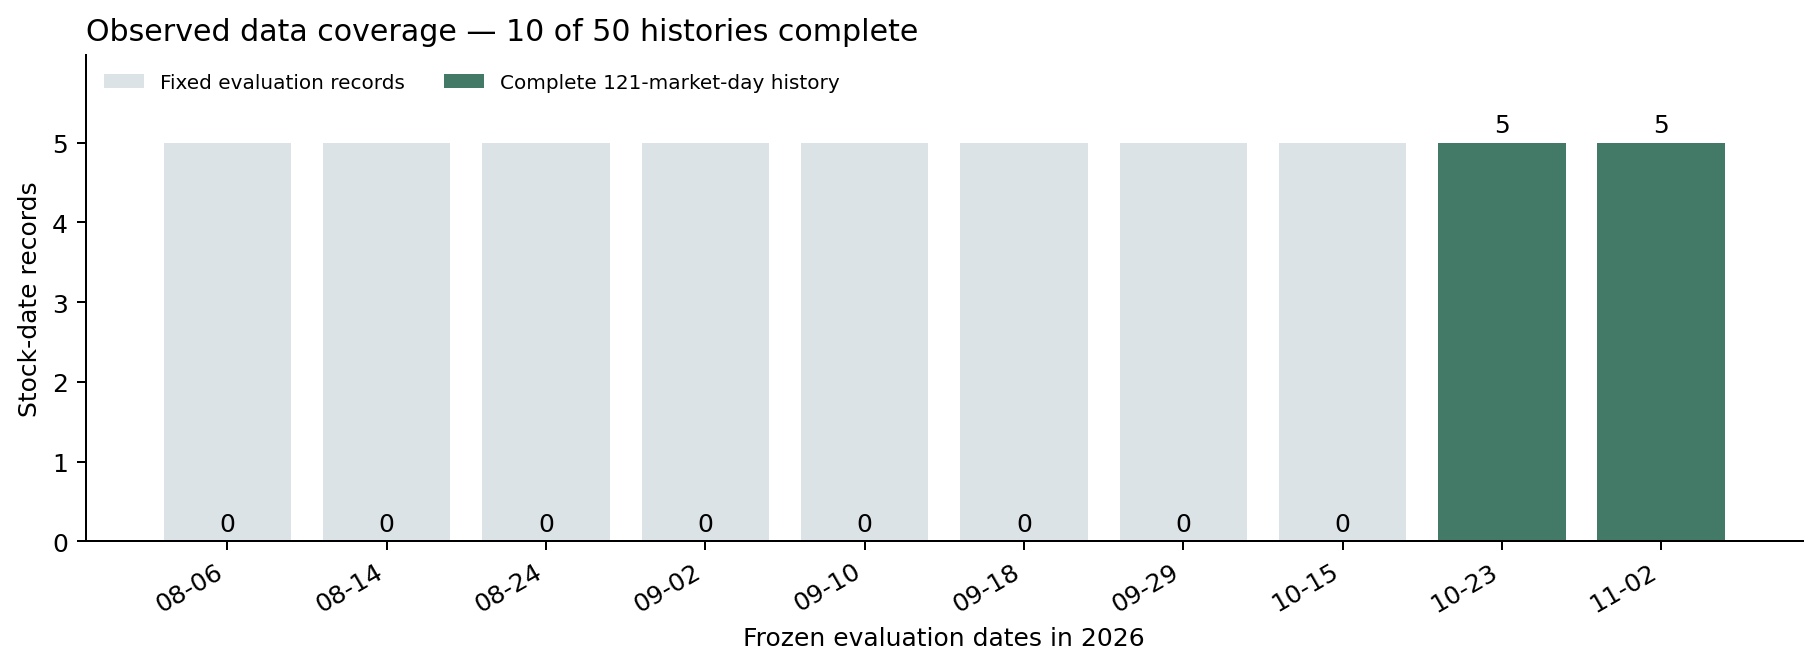

图：每个固定评价日期安排5条记录，完整121市场日历史的记录仅用于数据质量计数。不是预测结果。


In [4]:
quality_path=reports/'data_quality_summary.json'
if not quality_path.is_file():
    print('公开数据质量汇总尚未保存；不补造覆盖统计。')
else:
    quality=json.loads(quality_path.read_text(encoding='utf-8'))
    assert quality.get('schema')=='compact_pilot_data_quality_summary_v1'
    print('质量核查观察时间（UTC）：',quality.get('observed_utc','未记录'))
    print('核实的最新行情日期：',quality.get('latest_date','未冻结'))
    rows=[('目录可见CSV',quality['directory_visible_csv_files']),
          ('2019年后有记录的证券文件',quality['source_files_with_rows_since2019']),
          ('满足验证前股票池资格',quality['eligible_stocks']),
          ('已冻结股票数',quality['selected_stocks']),
          ('验证区特征合格记录',quality['validation_feature_valid_pool_rows']),
          ('固定评价记录历史完整',quality['evaluation_history_passes']),
          ('固定评价记录历史不完整',quality['evaluation_history_failures'])]
    display(Markdown('\n'.join(['|数据核查对象|数量|','|---|---:|']+
                              [f'|{name}|{number:,}|' for name,number in rows])))
    allocation=quality['allocation']
    assert sum(allocation.values())==quality['selected_stocks']==50
    assert quality['evaluation_history_passes']+quality['evaluation_history_failures']==50
    print('冻结股票池：沪市',allocation.get('sh',0),'；深市',allocation.get('sz',0),'；北交所',allocation.get('bj',0))
    missing=quality['common_missing_market_dates']
    assert len(set(missing))==len(missing)
    assert quality['common_missing_stock_date_records']==len(missing)*quality['selected_stocks']
    print('全部冻结股票共同缺失的开市日：',len(missing),'个；证券—日期缺失记录',quality['common_missing_stock_date_records'],'条。')
    print('共同缺失区间：',min(missing),'至',max(missing))
    by_date=quality['evaluation_history_by_date']
    assert len(by_date)==10 and sum(row['assigned'] for row in by_date)==50
    assert sum(row['history_complete'] for row in by_date)==quality['evaluation_history_passes']
    print('首先触发的停止阶段：',quality['first_stop_phase'],'；代码：',quality['first_stop_code'])
    print('缺失原因尚未独立查明。完整历史是必要条件，不能据此将10条记录全部判定为特征合格。')
    history_plot=reports/'data_history_coverage.png'
    if history_plot.is_file():
        display(Image(filename=str(history_plot)))
        print('图：每个固定评价日期安排5条记录，完整121市场日历史的记录仅用于数据质量计数。不是预测结果。')
    else:
        print('数据覆盖图尚未保存；以已保存汇总表为准。')

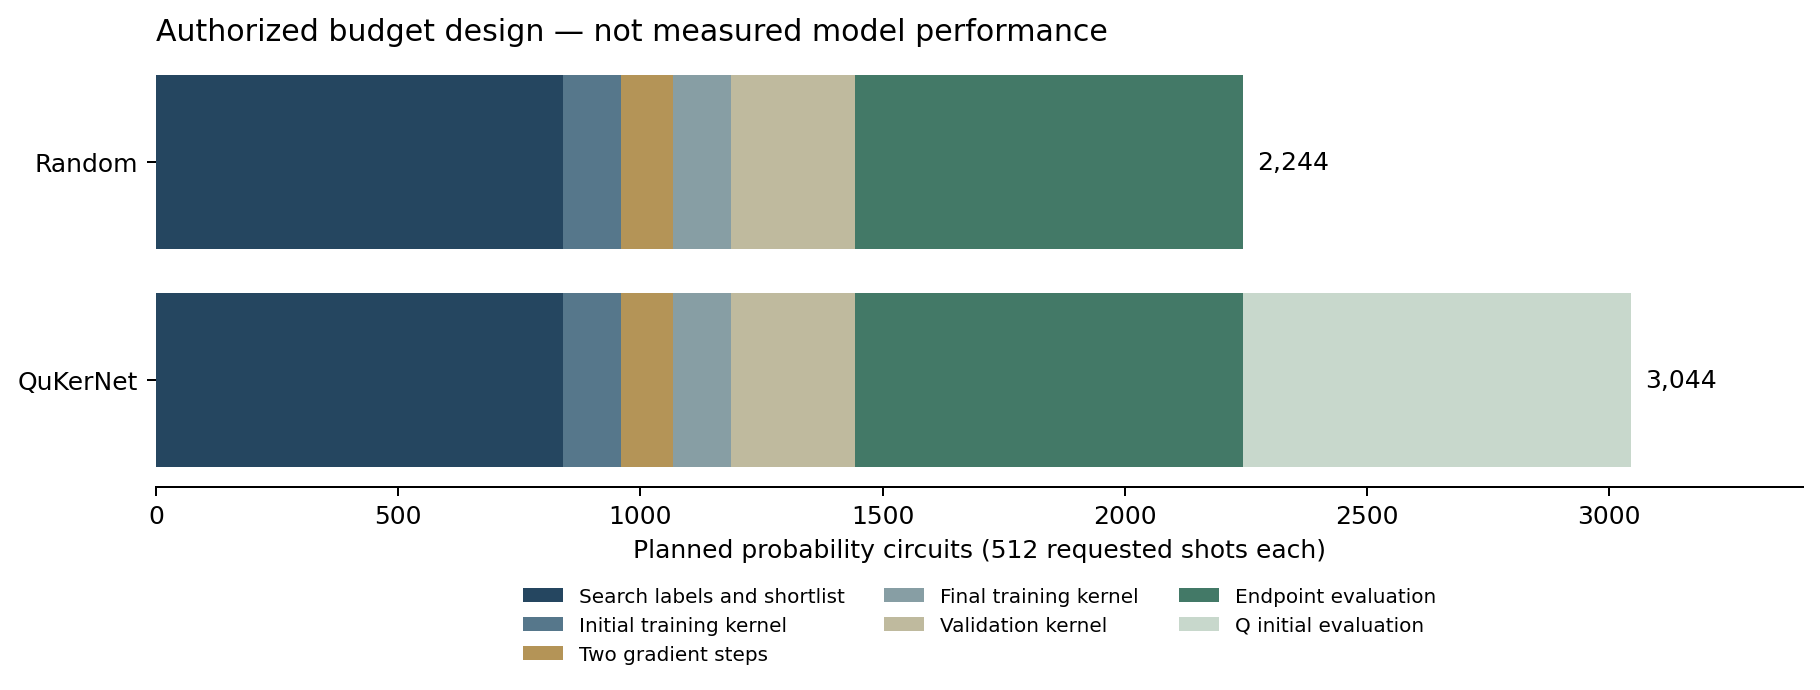

图示为计划预算，不是已执行实验曲线。


In [5]:
# 此图由制作流程按冻结预算生成；只展示现有公开文件，不触发实验。
plots=[reports/'planned_budget.png',reports/'figures/planned_budget.png']
budget_plot=next((p for p in plots if p.is_file()),None)
if budget_plot is None:
    print('预算图尚未保存；上方可复算的预算表仍有效。')
else:
    display(Image(filename=str(budget_plot)))
    print('图示为计划预算，不是已执行实验曲线。')

## 3. 什么结果才回答研究问题

分类KTA使用同类为+1、异类为−1的矩阵 $Y$：

\[
\operatorname{KTA}(K,Y)=\frac{\langle K,Y\rangle_F}{\|K\|_F\|Y\|_F}.
\]

参数移位先估计核概率导数，包含重叠线路两端的参数依赖，再通过链式法则求KTA梯度。对KTA本身直接作简单概率移位不等价。

在本轮8特征、单编码块、深度1的结构中，末端相同纠缠层在内积中抵消；某个编码门替换成两端共同的参数后，该比特的共同旋转也抵消。因此这类线路对替换参数的理想保真度核梯度为零。有限shots测得非零梯度可能只是采样误差，不能据此声称有有效微调自由度。深度2、3需按实际线路检查。输入8列也不保证8列均有变化或线性独立，结果需报告缩放后有效列数与秩。

完成后分别看三项配对：QuKerNet终点减同线路、同替换位置的自身初值；QuKerNet终点减随机搜索终点；QuKerNet终点减RBF。初值与终点分别重新拟合SVC。只有一个量子配置，所以该诊断不代表多配置搜索已经充分验证。

评价先在每个日期内平均，再对10个日期等权；50条股票记录不是50个独立市场日期。日期块重采样以块长2为主、1和3为敏感性，各10,000次，区间只作探索性描述。KTA提高而后续准确率不改善，仅支持训练代理目标被优化。

全训练历史的额外线性模型采用LinearSVC、平方hinge、固定迭代上限；受控16样本经典线性模型为线性核SVC。两者同时改变了样本量和求解器/损失，不能解释成纯粹增加训练数据的对照。

In [6]:
summary_path=reports/'summary.json'
if not summary_path.is_file() or not status.get('research_results_available',False):
    print('完整效果汇总待运行或待发布；不生成量子准确率、KTA或微调收益占位值。')
else:
    summary=json.loads(summary_path.read_text(encoding='utf-8'))
    print('汇总流程状态：',summary.get('workflow_status',summary.get('state','未记录')))
    arms=summary.get('arms',{})
    found=False
    for arm in ('qukernet','random'):
        item=arms.get(arm,{})
        metrics=item.get('O',{})
        if isinstance(metrics,dict) and isinstance(metrics.get('date_equal_accuracy'),(int,float)):
            print(arm,'季度/评价区日期等权准确率：',f"{metrics['date_equal_accuracy']:.2%}")
            found=True
    if not found:
        print('汇总尚无可识别的两臂评价指标，请核对结果格式，不能补造数值。')

完整效果汇总待运行或待发布；不生成量子准确率、KTA或微调收益占位值。


## 4. 练习与验收

1. 从16条训练记录、4条微调记录和2个参数复算1444条公共配额；指出哪些对角核为解析值。
2. 解释“256个候选的经典预测”为什么不等于256次云端核评价。
3. 给出KTA上升而股票准确率下降时可以写的结论。
4. 解释为什么必须把未运行、明确失败、观察超时与后台取消分开。
5. 如只完成一臂，列出哪些比较尚不能计算，并保留已发生的资源成本。

验收依据是协议与预算一致、已保存状态如实显示、效果缺失不填值。没有改善、无法辨认或证据不足也是可以报告的结果。本先导不提供正式策略净收益，不证明未来盈利或量子优势。

[完整协议](../../experiments/qukernet_finance/cloud_v3/protocol.json) · [实现说明](../../experiments/qukernet_finance/cloud_v3/README.md) · [公开状态](../../reports/qukernet_cloud_v3/status.json)

[本地离线环境](../../experiments/qukernet_finance/cloud_v3/环境版本记录.md) · [显式解析数值检查](../../experiments/qukernet_finance/cloud_v3/numerical_checks.py)
